# The 1D heat equation: two three-level schemes

$$\frac{\partial T}{\partial t} = \alpha\,\frac{\partial^2 T}{\partial x^2}$$

differenced using central in time schemes: Richardson (CTCS) and DuFort-Frankel. 

We use the same grid, ICs/BCs and  $r$ factor as in the nb05 notebook, so the results can be compared with the 3 schemes there.


## Set-up: grid, ICs/BCs, and the time levels to plot

In [22]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

### 1. Domain Definition (grid creation):

In [23]:
# Steps
dt = 0.025 # Time step -> delta_t
dx = 0.1 # Step size -> delta_x

# Diffusion coefficient:
alpha = 0.5

# Define the r factor
r_factor = alpha*dt/dx**2 # no condition on r for either scheme here
print("r factor is:  ", r_factor)

r factor is:   1.2499999999999998


In [24]:
# Limit for the spatial vector
a = 1.0

# Limit for the time vector
b = 0.5

# Axes
# Spatial axis
x = np.arange(0., a + dx , dx)

# Time axis, rounding it to 3 figs. is for plotting only
t = np.arange(0., b + dt , dt).round(5)

#print(x.shape)
#print(t.shape)

### 2. Set up ICs/BCs:

In [25]:
# Initial conditions
ics = np.sin(np.pi*x) # this is the initial T at t=0

# Boundary Conditions
bcs = [0., 0.] # T = 0 at x=0, and x=a

# Number of points on each axis
ni = len(x)
nt = len(t)

#print(ni, nt)

### 3. The time levels we will plot:

In [26]:
# Columns of T to draw
n_show = [0, 1, 2, 4, 8, nt - 1]

print(t[n_show])

[0.    0.025 0.05  0.1   0.2   0.5  ]


### 4. The exact solution, and the second time level:

For this IC and these BCs the heat equation has the closed-form solution

$$T(x,t) = e^{-\alpha \pi^{2} t}\,\sin(\pi x),$$

which we keep for two reasons: to measure the error at the end, and to supply
the **second time level** that both schemes need in order to start. Starting
them with one FTCS step would work too, but at this $r$ that step is itself
unstable and would pollute the comparison.

In [27]:
# The exact solution on the whole grid
T_exact = np.zeros((ni, nt))

for n in range(nt):
    T_exact[:, n] = np.exp(-alpha*np.pi**2*t[n])*np.sin(np.pi*x)

#print(T_exact.round(4).T)

# Richardson's method (CTCS: Central in Time, Central in Space)

Central differences in time as well as in space:

**Central difference in time:**
$$ T_{t} \approx \frac{T_{i}^{\,n+1} - T_{i}^{\,n-1}}{2\,\Delta t}
 + \mathcal{O}\!\left[(\Delta t)^2\right]. $$

**Central difference in space:**
$$ T_{xx} \approx \frac{T_{i+1}^{\,n} - 2T_{i}^{\,n} + T_{i-1}^{\,n}}{(\Delta x)^2}
 + \mathcal{O}\!\left[(\Delta x)^2\right]. $$

Then,
$$ \frac{T_{i}^{\,n+1} - T_{i}^{\,n-1}}{2\,\Delta t}
 = \alpha\,\frac{T_{i+1}^{\,n} - 2T_{i}^{\,n} + T_{i-1}^{\,n}}{(\Delta x)^2}, $$

$$ \Rightarrow \quad
T_{i}^{\,n+1} = T_{i}^{\,n-1}
 + 2r\left(T_{i+1}^{\,n} - 2T_{i}^{\,n} + T_{i-1}^{\,n}\right). $$

Second order in time **and** in space, and explicit, so by the measures of
Lecture 11 it is the best of the schemes we have written down.

**Stability.**

Three time levels give a *quadratic* in $G$,

$$ G^{2} + 2bG - 1 = 0, \qquad b = 4r\sin^{2}\tfrac{\beta}{2} \ge 0, $$

whose roots multiply to $-1$. One of them therefore always lies outside the
unit circle:

$$ \left|G_{-}\right| = b + \sqrt{b^{2}+1} \;>\; 1
\quad \text{for every } r > 0. $$

**Unconditionally unstable.** No time step saves it.

### 1. Solution matrix, with the ICs/BCs and the second level in place:

In [28]:
# Empty matrix with the correct size
T_ctcs = np.zeros((ni, nt))

# Fill up the initial conditions
T_ctcs[:, 0] = ics

# Fill up the second time level, needed to start a 3-level scheme
T_ctcs[:, 1] = T_exact[:, 1]

# Fill up the boundary conditions
T_ctcs[0 , :] = bcs[0]
T_ctcs[-1, :] = bcs[1]

#print(T_ctcs.round(4).T)

### 2. Fill up the inner elements of the matrix using the CTCS formula:

$$T_{i}^{\,n+1} = T_{i}^{\,n-1}
 + 2r\left(T_{i+1}^{\,n} - 2T_{i}^{\,n} + T_{i-1}^{\,n}\right)$$

In [29]:
# outer loop (time loop -> index n)
for n in range(1, nt - 1): # From 1, as levels 0 and 1 are already there

    # inner loop (spatial loop -> index i)
    for i in range(1, ni - 1): # From 1 to ni-1 as we already have the BCs set
        # CTCS formula
        T_ctcs[i, n+1] = T_ctcs[i, n-1] + 2*r_factor*(T_ctcs[i+1, n] - 2*T_ctcs[i, n] + T_ctcs[i-1, n])

### 3. Plotting the solution for $T(x,t)$:

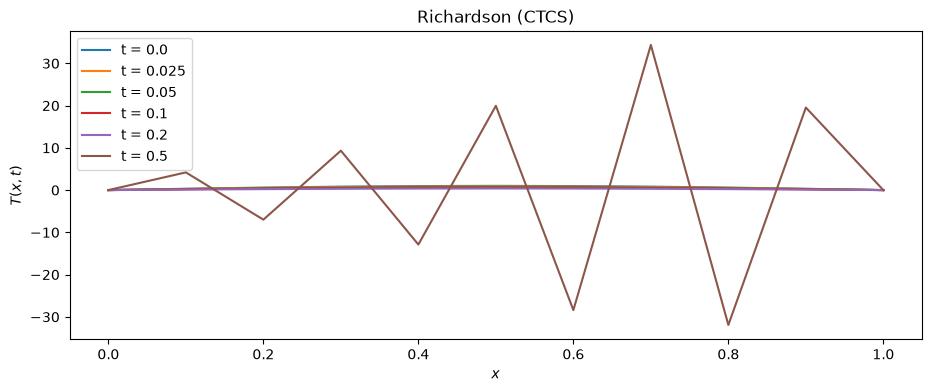

In [30]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, T_ctcs[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("Richardson (CTCS)")

plt.legend()

plt.show()

# DuFort-Frankel

The repair: keep the central time difference, but replace the centre value
$T_{i}^{\,n}$ in the space difference by the average of the two levels either
side of it,

$$ T_{i}^{\,n} \;\longrightarrow\; \frac{T_{i}^{\,n+1} + T_{i}^{\,n-1}}{2}, $$

so that

$$ \frac{T_{i}^{\,n+1} - T_{i}^{\,n-1}}{2\,\Delta t}
 = \frac{\alpha}{(\Delta x)^2}
 \left(T_{i+1}^{\,n} - T_{i}^{\,n+1} - T_{i}^{\,n-1} + T_{i-1}^{\,n}\right). $$

The unknown now appears on both sides, but only at the point $i$, so it can
still be solved for by hand — the scheme stays **explicit**:

$$ T_{i}^{\,n+1}\left(1 + 2r\right)
 = \left(1 - 2r\right)T_{i}^{\,n-1}
 + 2r\left(T_{i+1}^{\,n} + T_{i-1}^{\,n}\right), $$

$$ \Rightarrow \quad
T_{i}^{\,n+1} = \frac{\left(1 - 2r\right)T_{i}^{\,n-1}
 + 2r\left(T_{i+1}^{\,n} + T_{i-1}^{\,n}\right)}{1 + 2r}. $$

**Stability.**

$$ (1+2r)G^{2} - 4r\cos\beta\,G - (1-2r) = 0
\quad\Longrightarrow\quad |G| \le 1 \ \text{ for every } r. $$

**Unconditionally stable**, and explicit.

### 1. Solution matrix, with the ICs/BCs and the second level in place:

In [31]:
# Empty matrix with the correct size
T_duff = np.zeros((ni, nt))

# Fill up the initial conditions
T_duff[:, 0] = ics

# Fill up the second time level, needed to start a 3-level scheme
T_duff[:, 1] = T_exact[:, 1]

# Fill up the boundary conditions
T_duff[0 , :] = bcs[0]
T_duff[-1, :] = bcs[1]

#print(T_duff.round(4).T)

### 2. Fill up the inner elements of the matrix using the DuFort-Frankel formula:

$$T_{i}^{\,n+1} = \frac{\left(1 - 2r\right)T_{i}^{\,n-1}
 + 2r\left(T_{i+1}^{\,n} + T_{i-1}^{\,n}\right)}{1 + 2r}$$

In [32]:
# outer loop (time loop -> index n)
for n in range(1, nt - 1): # From 1, as levels 0 and 1 are already there

    # inner loop (spatial loop -> index i)
    for i in range(1, ni - 1): # From 1 to ni-1 as we already have the BCs set
        # DuFort-Frankel formula
        T_duff[i, n+1] = ((1 - 2*r_factor)*T_duff[i, n-1] + 2*r_factor*(T_duff[i+1, n] + T_duff[i-1, n]))/(1 + 2*r_factor)

### 3. Plotting the solution for $T(x,t)$:

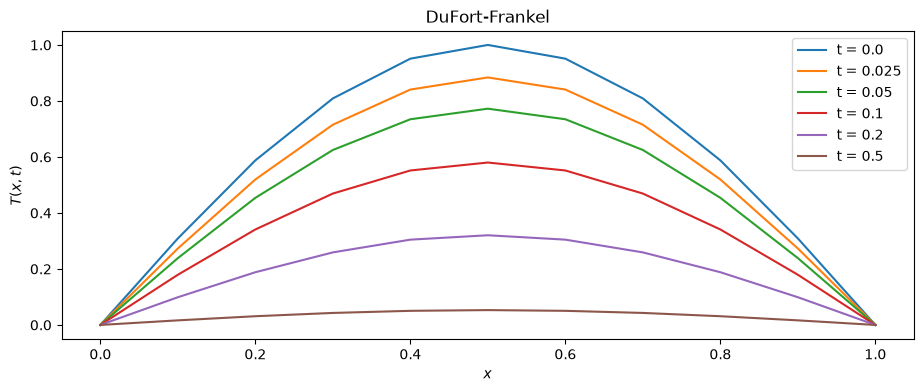

In [33]:
# Fig environment
plt.figure(figsize=(11,4))

for n in n_show:
    plt.plot(x, T_duff[:, n], label = f"t = {t[n]}")

plt.xlabel(r"$x$")
plt.ylabel(r"$T(x,t)$")

plt.title("DuFort-Frankel")

plt.legend()

plt.show()

# Comparing the two schemes

Same grid, same ICs/BCs, same $r$, same second time level, so the only
difference is the formula.

In [34]:
# List of schemes
slns  = [T_ctcs, T_duff]
names = ["Richardson (CTCS)", "DuFort-Frankel"]

#### A. Temperature vs. position, scheme by scheme:

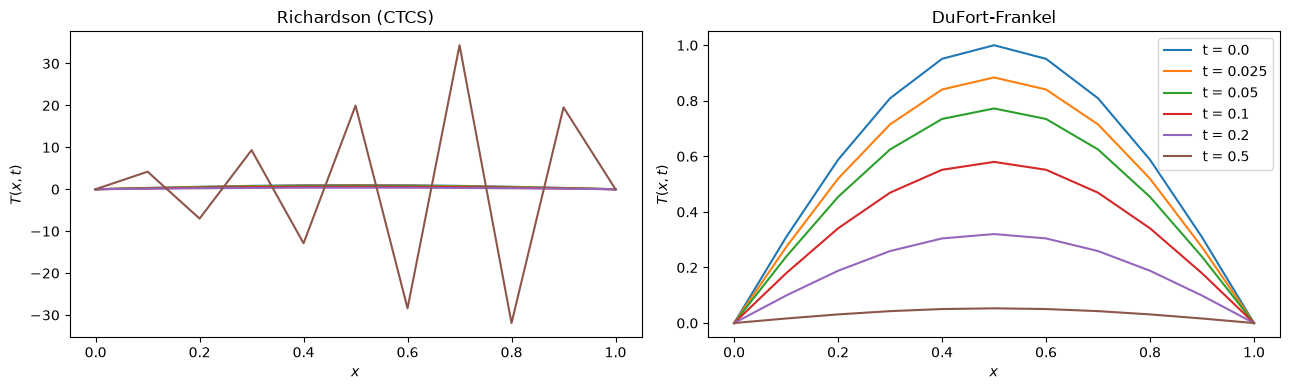

In [35]:
plt.figure(figsize=(13,4))

for k in range(2):

    plt.subplot(1, 2, k + 1)

    for n in n_show:
        plt.plot(x, slns[k][:, n], label = f"t = {t[n]}")

    plt.xlabel(r"$x$")
    plt.ylabel(r"$T(x,t)$")
    plt.title(names[k])

plt.legend()

plt.tight_layout()

plt.show()

#### B. Temperature surface projection: DuFort-Frankel

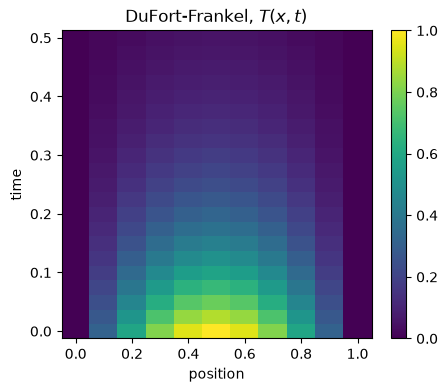

In [36]:
# Create 2D grid using meshgrid
x_grid, t_grid = np.meshgrid(x, t)

plt.figure(figsize=(5,4))

z_temp = plt.pcolor(x_grid, t_grid, T_duff.T, cmap = 'viridis')

plt.xlabel("position")

plt.ylabel("time")

plt.title("DuFort-Frankel, $T(x, t)$")

plt.colorbar(z_temp)

plt.show()

# An important note on DuFort-Frankel:

DuFort-Frankel is stable for every $r$, and the catch is in the truncation error. Expanding every term about $(i,n)$ gives

$$ T_{t} = \alpha T_{xx}
 \;-\; \alpha\left(\frac{\Delta t}{\Delta x}\right)^{2} T_{tt}
 \;+\; \mathcal{O}\!\left[(\Delta t)^{2}, (\Delta x)^{2}\right]. $$

That extra term vanishes under refinement only if $\Delta t/\Delta x \to 0$. Hold the ratio fixed at $\Delta t/\Delta x = R$ and refine, and the scheme converges beautifully to the solution of

$$ T_{t} + \alpha R^{2} T_{tt} = \alpha T_{xx}, $$

a damped wave equation, which is not the problem we posed. So, it is **stable and consistent only in a limit.**

Below, the same march is run on four meshes in two different ways, and the error at $t = 0.5$ is measured against the exact solution:

- $\Delta t/\Delta x$ held fixed at 0.25 -> the error should stall.

- $r$ held fixed at 0.4, i.e. $\Delta t \sim (\Delta x)^2$ -> the error should fall like $(\Delta x)^2$.

In [37]:
# Refine the mesh in two different ways, with the same march inside

dx_list = [0.1, 0.05, 0.025, 0.0125]

dt_ratio = [0.25*dx_try for dx_try in dx_list]           # dt/dx = 0.25
dt_rfix  = [0.40*dx_try**2/alpha for dx_try in dx_list]   # r = 0.4

err_ratio = []
err_rfix  = []

for dt_list, err_list, label in [(dt_ratio, err_ratio, "dt/dx fixed at 0.25"), (dt_rfix,  err_rfix,  "r fixed at 0.4")]:

    print(label)

    for dx_try, dt_try in zip(dx_list, dt_list):

        r_try = alpha*dt_try/dx_try**2

        x_try = np.arange(0., a + dx_try , dx_try)
        t_try = np.arange(0., b + dt_try , dt_try)

        ni_try = len(x_try)
        nt_try = len(t_try)

        # Same set-up as above: ICs, BCs, and the second level from the exact sln
        T_try = np.zeros((ni_try, nt_try))

        T_try[:, 0] = np.sin(np.pi*x_try)
        T_try[:, 1] = np.exp(-alpha*np.pi**2*t_try[1])*np.sin(np.pi*x_try)

        T_try[0 , :] = bcs[0]
        T_try[-1, :] = bcs[1]

        # Same DuFort-Frankel formula as above
        for n in range(1, nt_try - 1):
            for i in range(1, ni_try - 1):
                T_try[i, n+1] = ((1 - 2*r_try)*T_try[i, n-1] + 2*r_try*(T_try[i+1, n] + T_try[i-1, n]))/(1 + 2*r_try)

        exact_try = np.exp(-alpha*np.pi**2*t_try[-1])*np.sin(np.pi*x_try)

        err_list.append(np.max(np.abs(T_try[:, -1] - exact_try)))

        print("   dx =", dx_try, "  dt =", round(dt_try, 6), "  r =", round(r_try, 3), "  max error =", round(err_list[-1], 6))

dt/dx fixed at 0.25
   dx = 0.1   dt = 0.025   r = 1.25   max error = 0.031791
   dx = 0.05   dt = 0.0125   r = 2.5   max error = 0.033693
   dx = 0.025   dt = 0.00625   r = 5.0   max error = 0.034261
   dx = 0.0125   dt = 0.003125   r = 10.0   max error = 0.034449
r fixed at 0.4
   dx = 0.1   dt = 0.008   r = 0.4   max error = 0.001529
   dx = 0.05   dt = 0.002   r = 0.4   max error = 0.000394
   dx = 0.025   dt = 0.0005   r = 0.4   max error = 9.9e-05
   dx = 0.0125   dt = 0.000125   r = 0.4   max error = 2.5e-05


#### Comparison:

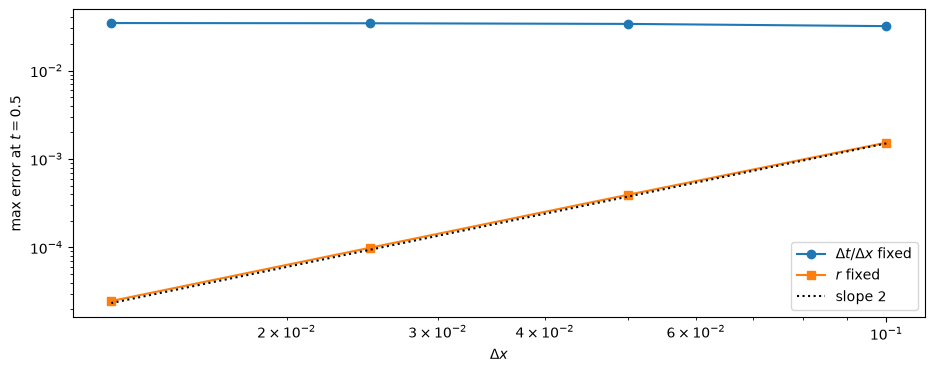

In [38]:
plt.figure(figsize=(11,4))

plt.loglog(dx_list, err_ratio, "o-", label = r"$\Delta t / \Delta x$ fixed")
plt.loglog(dx_list, err_rfix , "s-", label = r"$r$ fixed")

plt.loglog(dx_list, [0.15*dx_try**2 for dx_try in dx_list], "k:",
           label = r"slope 2")

plt.xlabel(r"$\Delta x$")
plt.ylabel(r"max error at $t = 0.5$")

plt.legend()

plt.show()

### Observations:

- With $r$ held fixed the error falls by a factor of four every time the mesh is halved: thus, the method is second order.

- With $\Delta t/\Delta x$ held fixed the error flattens out and refining the mesh stops helping, because the scheme is no longer solving the heat equation in that limit.

- Neither curve ever blows up: DuFort-Frankel really is unconditionally stable.

- Stability, consistency and order are separate properties, and this scheme fails only the second.